# 07 - Free vibrations: the mass-spring-damper system

**MATH 331 - Differential Equations.** Lecture plan: Session 14 (Unit 6: free and damped vibrations; classify a spring-mass system by its damping).

**References**
* J. Lebl, *Notes on Diffy Qs*: **Section 2.4, Mechanical vibrations**: the model, Example 2.4.1
  (free undamped motion, amplitude and phase), the notation $\omega_0 = \sqrt{k/m}$ and
  $p = c/(2m)$, Example 2.4.2 (overdamped), critical damping, underdamping and the envelope.
* W.A. Adkins and M.G. Davidson, *Ordinary Differential Equations* (Springer, 2012): **Section
  3.6, Spring Systems** (Examples 2 and 3) and **Section 3.7, RCL Circuits** (Table 3.4, the
  correspondence between the spring and the circuit).
* Related notebooks: 06 (the characteristic equation: this notebook is its three cases, with
  physical names), 13 (first-order circuits), **07E** (optional). Video R05 (complex numbers).

**What you will learn**
1. How Newton's law, Hooke's law and a damper give $m\,x'' + c\,x' + k\,x = 0$.
2. Free motion without damping: frequency, amplitude and phase.
3. The three kinds of damped motion, and how to tell which one you have **before solving**.
4. Why an electrical circuit with a coil, a resistor and a capacitor behaves in the same way.

## 1. Theory in brief

**The model.** A body of mass $m$ on a spring of stiffness $k$, with a damper of coefficient $c$;
$x(t)$ is the displacement from the rest position:

$$ \boxed{\;m\,x'' + c\,x' + k\,x = 0\;} \qquad m > 0,\ k > 0,\ c \ge 0 . $$

**Two numbers** (Lebl's notation): the natural angular frequency $\omega_0 = \sqrt{\dfrac km}$ and
$p = \dfrac{c}{2m}$. The equation becomes $x'' + 2p\,x' + \omega_0^2\,x = 0$, with characteristic
roots $r = -p \pm \sqrt{p^2 - \omega_0^2}$ (notebook 06).

**Critical damping:** $c_{crit} = 2\sqrt{mk}$ (where $p = \omega_0$).

| Kind of motion | Condition | Roots | Solution |
|---|---|---|---|
| undamped | $c = 0$ | $\pm i\,\omega_0$ | $C_1\cos\omega_0 t + C_2\sin\omega_0 t$ |
| underdamped | $0 < c < c_{crit}$ | $-p \pm i\,\omega_1$, $\ \omega_1 = \sqrt{\omega_0^2 - p^2}$ | $e^{-pt}\,(C_1\cos\omega_1 t + C_2\sin\omega_1 t)$ |
| critically damped | $c = c_{crit}$ | $-p$, repeated | $(C_1 + C_2\,t)\,e^{-pt}$ |
| overdamped | $c > c_{crit}$ | two negative real roots | $C_1e^{r_1t} + C_2e^{r_2t}$ |

**One cosine.** $C_1\cos\omega t + C_2\sin\omega t = A\cos(\omega t - \gamma)$, with the
**amplitude** $A = \sqrt{C_1^2 + C_2^2}$ and the **phase** $\gamma$, the angle of the point $(C_1, C_2)$:
$\cos\gamma = C_1/A$, $\sin\gamma = C_2/A$ (so $\tan\gamma = C_2/C_1$, with $\gamma$ in the quadrant of that point).

**With any damping, $c > 0$, every motion dies out:** both roots have a negative real part.

In [1]:
# --- Setup ---------------------------------------------------------------------
# odelib.py lives next to the notebooks: it contains the tested helper functions
# (here: free_response, damping_regime, characteristic_roots, check).
import sys
import pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from IPython.display import Math, display                 # noqa: F401  (not used in every notebook)
from ipywidgets import FloatSlider, IntSlider, interact    # noqa: F401

import odelib as ol

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 11, "legend.fontsize": 9})
print("numpy", np.__version__, "| sympy", sp.__version__)

numpy 2.5.4 | sympy 1.14.0


## 2. The model

A body of mass $m$ is attached to a spring and to a damper (a piston in oil: a door closer, a
shock absorber). $x(t)$ is its displacement from the position of rest. Three forces act on it
(Lebl, Section 2.4; Adkins and Davidson, Section 3.6):

* the **spring** (Hooke's law): $-k\,x$, always pulling back towards the rest position;
* the **damper**: $-c\,x'$, proportional to the velocity and against it;
* an external force $F(t)$, which is zero in this notebook: the motion is *free*.

Newton's second law, $m\,x'' = $ sum of the forces, gives $\;m\,x'' + c\,x' + k\,x = 0$.

*A vertical spring.* Gravity adds the constant force $mg$. If $x$ is measured from the position
where the body hangs at rest, the constant cancels and the equation is the same. This is how $k$
is measured: a weight $mg$ stretches the spring by $\Delta\ell$, and $k = mg/\Delta\ell$.

*Units (SI).* $m$ in kg, $k$ in N/m, $c$ in N s/m.

*A pendulum* of length $L$ obeys $\theta'' + \dfrac gL\sin\theta = 0$; for small swings
$\sin\theta \approx \theta$ and it is this equation with $c = 0$ and $k/m = g/L$.

## 3. Free motion without damping

With $c = 0$ the roots are $\pm i\,\omega_0$ and

$$ x = C_1\cos\omega_0 t + C_2\sin\omega_0 t, \qquad C_1 = x(0), \quad C_2 = \frac{x'(0)}{\omega_0} . $$

The period is $T = \dfrac{2\pi}{\omega_0}$, the frequency $\dfrac{\omega_0}{2\pi}$ hertz: they
depend on $m$ and $k$ only, **not** on how hard the body was pushed.

*Lebl, Example 2.4.1.* $m = 2$ kg, $k = 8$ N/m; at $t = 0$ the mass is 0.5 m from rest and moves
at 1 m/s. By hand:

* $2x'' + 8x = 0$, $\;\omega_0 = \sqrt{8/2} = 2$ rad/s, frequency $\dfrac{2}{2\pi} \approx 0.318$ Hz;
* $C_1 = 0.5$, $C_2 = \dfrac{1}{2} = 0.5$: $\;x = 0.5\cos 2t + 0.5\sin 2t$;
* amplitude $A = \sqrt{0.5^2 + 0.5^2} = \sqrt{0.5} \approx 0.707$ m; phase
  $\gamma = \arctan\dfrac{0.5}{0.5} = \dfrac\pi4 \approx 0.785$: $\;x = 0.707\cos(2t - 0.785)$.

In code the phase is `np.arctan2(C2, C1)`, which chooses the right quadrant by itself (Lebl's
note in Section 2.4 explains why a plain arctangent is not enough).

omega_0 = 2 rad/s, frequency = 0.318 Hz, period = 3.142 s
C1 = 0.5, C2 = 0.5, amplitude = 0.707 m, phase = 0.785 rad


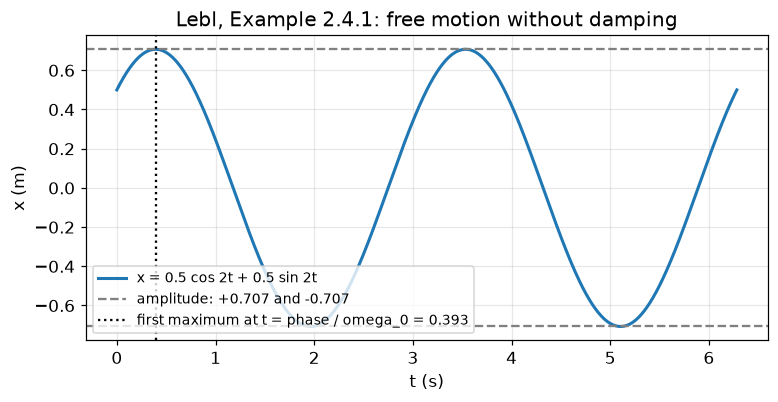

In [2]:
MASS, STIFFNESS = 2.0, 8.0                  # Lebl, Example 2.4.1: kg, N/m
X_START, V_START = 0.5, 1.0                 # m, m/s
FIGURE_SIZE = (8.0, 3.6)
N_POINTS = 600

omega_0 = np.sqrt(STIFFNESS / MASS)
C_1, C_2 = X_START, V_START / omega_0
amplitude, phase = np.hypot(C_1, C_2), np.arctan2(C_2, C_1)
print(f"omega_0 = {omega_0:g} rad/s, frequency = {omega_0 / (2 * np.pi):.3f} Hz, period = {2 * np.pi / omega_0:.3f} s")
print(f"C1 = {C_1:g}, C2 = {C_2:g}, amplitude = {amplitude:.3f} m, phase = {phase:.3f} rad")

times = np.linspace(0.0, 2 * np.pi, N_POINTS)
motion = ol.free_response(times, MASS, 0.0, STIFFNESS, X_START, V_START)

fig, ax = plt.subplots(figsize=FIGURE_SIZE)
ax.plot(times, motion, "-", linewidth=2, label="x = 0.5 cos 2t + 0.5 sin 2t")
ax.axhline(amplitude, linestyle="--", color="gray", label=f"amplitude: +{amplitude:.3f} and -{amplitude:.3f}")
ax.axhline(-amplitude, linestyle="--", color="gray")
ax.axvline(phase / omega_0, linestyle=":", color="black", label=f"first maximum at t = phase / omega_0 = {phase / omega_0:.3f}")
ax.set_xlabel("t (s)")
ax.set_ylabel("x (m)")
ax.set_title("Lebl, Example 2.4.1: free motion without damping")
ax.legend(loc="lower left")
plt.show()

assert np.isclose(amplitude, np.sqrt(0.5)) and np.isclose(phase, np.pi / 4)             # the values of the book
assert np.allclose(motion, amplitude * np.cos(omega_0 * times - phase))                 # the form with one cosine

*The plot shows* two full swings of the motion over 6.28 seconds: a sine-like curve that starts
at 0.5, rises to its maximum 0.707 at $t = 0.393$ s (dotted vertical line), and then oscillates
for ever between the two dashed horizontal lines at $\pm 0.707$. The swings do not get smaller.

## 4. Damped motion: three kinds

Compare the damping $c$ with the critical value $c_{crit} = 2\sqrt{mk}$: this decides the kind of
motion, **before solving anything**. It is the sign of $c^2 - 4mk$, the discriminant of the
characteristic equation (notebook 06).

*Adkins and Davidson, Section 3.6, Example 2.* A force of 5 N stretches the spring 0.2 m, so
$k = 25$ N/m; the damper resists with 5 N at 0.5 m/s, so $c = 10$ N s/m; the mass is 4 kg.
$\;4x'' + 10x' + 25x = 0$. By hand: $c_{crit} = 2\sqrt{4 \cdot 25} = 20 > 10$: **underdamped**. The
body will oscillate while it comes to rest.

*Adkins and Davidson, Section 3.6, Example 3* (in the units of the book: pounds, feet, slugs):
$\;\tfrac18x'' + 4x' + 16x = 0$. $c_{crit} = 2\sqrt{\tfrac18\cdot 16} = 2\sqrt2 \approx 2.83 < 4$:
**overdamped**. No oscillation.

In [3]:
EXAMPLES = (("Adkins-Davidson, Example 2", 4.0, 10.0, 25.0),
            ("Adkins-Davidson, Example 3", 1 / 8, 4.0, 16.0))

for name, mass, damping, stiffness in EXAMPLES:
    critical = 2 * np.sqrt(mass * stiffness)
    first, second = ol.characteristic_roots(mass, damping, stiffness)
    print(f"{name}: c = {damping:g}, c_crit = {critical:.2f}  ->  {ol.damping_regime(mass, damping, stiffness)};  "
          f"roots {first:.3f} and {second:.3f}")

assert ol.damping_regime(*EXAMPLES[0][1:]) == "underdamped" and ol.damping_regime(*EXAMPLES[1][1:]) == "overdamped"

Adkins-Davidson, Example 2: c = 10, c_crit = 20.00  ->  underdamped;  roots -1.250+2.165j and -1.250-2.165j
Adkins-Davidson, Example 3: c = 4, c_crit = 2.83  ->  overdamped;  roots -4.686+0.000j and -27.314+0.000j


**The three kinds side by side.** The same mass and spring ($m = 1$, $k = 4$, so $\omega_0 = 2$
and $c_{crit} = 4$), released from rest at $x = 1$, with three dampers.

*Lebl, Example 2.4.2* gives the overdamped motion released from rest:
$\;x = \dfrac{x_0}{r_1 - r_2}\,\big(r_1e^{r_2t} - r_2e^{r_1t}\big)$; the code checks it against the
general formula of the library.

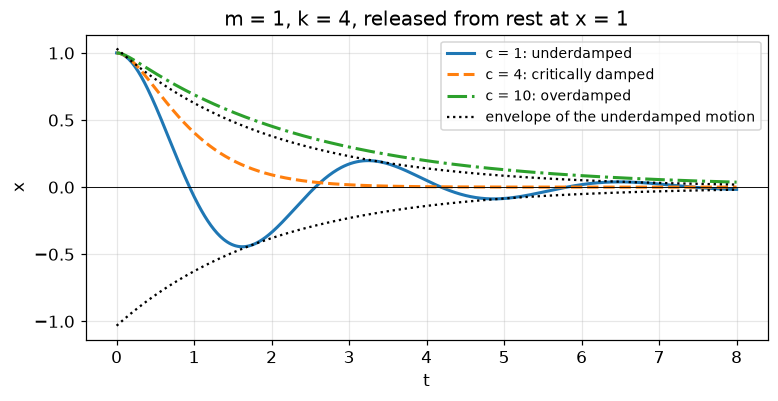

underdamped: p = 0.5, omega_1 = 1.936 (less than omega_0 = 2), swings 1.62 apart


In [4]:
UNIT_MASS, SPRING = 1.0, 4.0
DAMPINGS = (1.0, 4.0, 10.0)                 # below, at and above the critical value 4
STYLES = ("-", "--", "-.")
LONG_TIME = 8.0

times = np.linspace(0.0, LONG_TIME, N_POINTS)
fig, ax = plt.subplots(figsize=FIGURE_SIZE)
for damping, style in zip(DAMPINGS, STYLES):
    ax.plot(times, ol.free_response(times, UNIT_MASS, damping, SPRING, 1.0, 0.0), linestyle=style, linewidth=2,
            label=f"c = {damping:g}: {ol.damping_regime(UNIT_MASS, damping, SPRING)}")
p_light = DAMPINGS[0] / (2 * UNIT_MASS)
omega_1 = np.sqrt(SPRING / UNIT_MASS - p_light ** 2)
envelope = np.hypot(1.0, p_light / omega_1) * np.exp(-p_light * times)       # A exp(-p t) for the underdamped one
ax.plot(times, envelope, ":", color="black", label="envelope of the underdamped motion")
ax.plot(times, -envelope, ":", color="black")
ax.axhline(0.0, color="black", linewidth=0.6)
ax.set_xlabel("t")
ax.set_ylabel("x")
ax.set_title("m = 1, k = 4, released from rest at x = 1")
ax.legend(loc="upper right")
plt.show()

heavy = DAMPINGS[2]
root_1, root_2 = (root.real for root in ol.characteristic_roots(UNIT_MASS, heavy, SPRING))
lebl = 1.0 / (root_1 - root_2) * (root_1 * np.exp(root_2 * times) - root_2 * np.exp(root_1 * times))
assert np.allclose(lebl, ol.free_response(times, UNIT_MASS, heavy, SPRING, 1.0, 0.0))    # Lebl, Example 2.4.2
print(f"underdamped: p = {p_light:g}, omega_1 = {omega_1:.3f} (less than omega_0 = 2), swings {np.pi / omega_1:.2f} apart")

*The plot shows* three motions starting from $x = 1$ with zero velocity. With $c = 1$ (solid,
underdamped) the body swings through zero again and again, each swing smaller, inside the dotted
envelope. With $c = 4$ (dashed, critically damped) it returns to zero without crossing it, and
is practically at rest after $t = 4$. With $c = 10$ (dash-dot, overdamped) it also returns
without crossing, but **more slowly**: at $t = 4$ it is still at about 0.2.

Three things to read (Lebl, Section 2.4):

* underdamped: the oscillation is **slower** than without damping ($\omega_1 < \omega_0$), and its
  zeros are equally spaced, $\pi/\omega_1$ apart;
* critically damped and overdamped: the body passes through the rest position **at most once**
  (two real roots: notebook 06, Section 2; for the repeated root, $(C_1 + C_2t)\,e^{-pt}$ is zero
  only at $t = -C_1/C_2$);
* more damping is not better: beyond the critical value the return gets slower.

**Sliders.** Answer *before* moving them:

1. With $m = 1$ and $k = 4$, which value of $c$ brings the body back to rest fastest without
   oscillation?
2. The mass is made four times larger. What happens to the critical damping? And to the
   frequency of the undamped motion?
3. Can the body be made to cross the rest position **twice** when it is overdamped, by choosing
   the initial velocity?

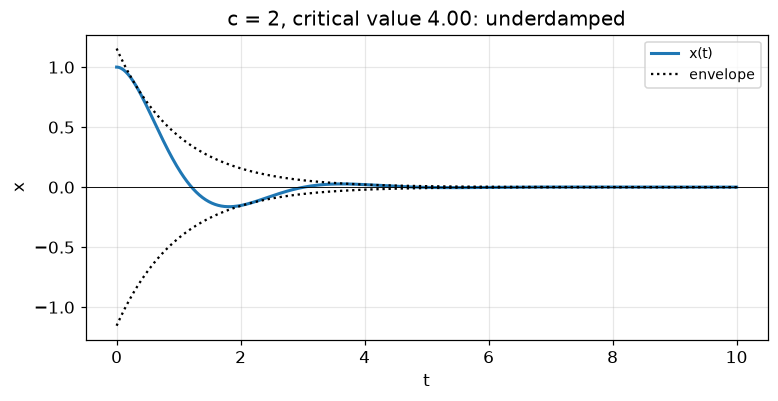

In [5]:
SLIDER_TIME = 10.0
DEFAULTS = {"c": 2.0, "m": 1.0, "k": 4.0, "x0": 1.0, "v0": 0.0}


def plot_response(c=DEFAULTS["c"], m=DEFAULTS["m"], k=DEFAULTS["k"], x0=DEFAULTS["x0"], v0=DEFAULTS["v0"],
                  t_end=SLIDER_TIME):
    # the motion for given mass, damper, spring and initial data, with the kind of motion in the title
    times = np.linspace(0.0, t_end, N_POINTS)
    critical = 2 * np.sqrt(m * k)
    kind = ol.damping_regime(m, c, k)
    fig, ax = plt.subplots(figsize=FIGURE_SIZE)
    ax.plot(times, ol.free_response(times, m, c, k, x0, v0), "-", linewidth=2, label="x(t)")
    if kind in ("underdamped", "undamped"):
        p = c / (2 * m)
        omega = np.sqrt(k / m - p ** 2)
        size = np.hypot(x0, (v0 + p * x0) / omega) * np.exp(-p * times)
        ax.plot(times, size, ":", color="black", label="envelope")
        ax.plot(times, -size, ":", color="black")
    ax.axhline(0.0, color="black", linewidth=0.6)
    ax.set_xlabel("t")
    ax.set_ylabel("x")
    ax.set_title(f"c = {c:g}, critical value {critical:.2f}: {kind}")
    ax.legend(loc="upper right")
    plt.show()


plot_response()

In [6]:
C_RANGE = (0.0, 12.0, 0.1)                  # minimum, maximum, step
M_RANGE = (0.25, 4.0, 0.25)
K_RANGE = (0.5, 16.0, 0.5)
X0_RANGE = (-2.0, 2.0, 0.1)
V0_RANGE = (-5.0, 5.0, 0.1)

interact(plot_response,
         c=FloatSlider(value=DEFAULTS["c"], min=C_RANGE[0], max=C_RANGE[1], step=C_RANGE[2], description="c",
                       continuous_update=False),
         m=FloatSlider(value=DEFAULTS["m"], min=M_RANGE[0], max=M_RANGE[1], step=M_RANGE[2], description="m",
                       continuous_update=False),
         k=FloatSlider(value=DEFAULTS["k"], min=K_RANGE[0], max=K_RANGE[1], step=K_RANGE[2], description="k",
                       continuous_update=False),
         x0=FloatSlider(value=DEFAULTS["x0"], min=X0_RANGE[0], max=X0_RANGE[1], step=X0_RANGE[2], description="x(0)",
                        continuous_update=False),
         v0=FloatSlider(value=DEFAULTS["v0"], min=V0_RANGE[0], max=V0_RANGE[1], step=V0_RANGE[2], description="x'(0)",
                        continuous_update=False));

interactive(children=(FloatSlider(value=2.0, continuous_update=False, description='c', max=12.0), FloatSlider(...

*The static plot shows* the motion for $c = 2$, half the critical value: an underdamped
oscillation from $x = 1$ whose swings shrink quickly inside the dotted envelope; after $t = 5$
it is practically at rest.

(1: the critical value, $c = 4$. 2: $c_{crit} = 2\sqrt{mk}$ doubles; $\omega_0 = \sqrt{k/m}$ is
halved. 3: no: at most once, whatever the initial data; try $x(0) = 1$ with a large negative
velocity to see the one crossing.)

## 5. The same equation in a circuit

A coil (inductance $L$), a resistor ($R$) and a capacitor ($C$) in series, with no battery. With
the laws of notebook 13 (Adkins and Davidson, Section 3.7), Kirchhoff's voltage law for the
charge $Q$ on the capacitor is

$$ L\,Q'' + R\,Q' + \frac1C\,Q = 0 . $$

It is the equation of the spring, letter by letter (Adkins and Davidson, Table 3.4):

| Spring | Circuit |
|---|---|
| displacement $x$ | charge $Q$ |
| velocity $x'$ | current $I = Q'$ |
| mass $m$ | inductance $L$ |
| damper $c$ | resistance $R$ |
| stiffness $k$ | $1/C$ |

So everything above holds for the circuit: the critical **resistance** is $2\sqrt{L/C}$, and
below it the charge oscillates while it dies out.

*Example.* $L = 0.5$ H, $R = 2$ ohm, $C = 0.08$ F; the capacitor starts with a charge of 1
coulomb and no current. By hand: $R_{crit} = 2\sqrt{0.5/0.08} = 5$ ohm $> 2$: underdamped.

critical resistance 5 ohm, R = 2 ohm: underdamped


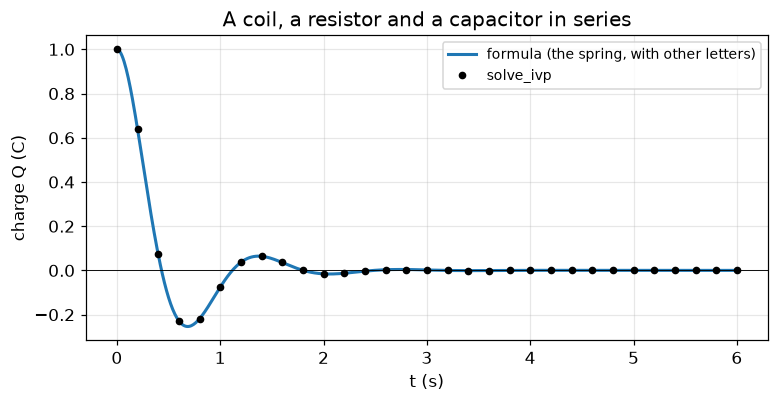

In [7]:
INDUCTANCE, RESISTANCE, CAPACITANCE = 0.5, 2.0, 0.08       # henry, ohm, farad
CIRCUIT_TIME = 6.0
N_DOTS = 31
TOLERANCE = 1e-10

critical_resistance = 2 * np.sqrt(INDUCTANCE / CAPACITANCE)
kind = ol.damping_regime(INDUCTANCE, RESISTANCE, 1 / CAPACITANCE)
print(f"critical resistance {critical_resistance:g} ohm, R = {RESISTANCE:g} ohm: {kind}")

times = np.linspace(0.0, CIRCUIT_TIME, N_POINTS)
dots = np.linspace(0.0, CIRCUIT_TIME, N_DOTS)
numerical = solve_ivp(lambda s, state: [state[1], -(RESISTANCE * state[1] + state[0] / CAPACITANCE) / INDUCTANCE],
                      (0.0, CIRCUIT_TIME), [1.0, 0.0], dense_output=True, rtol=TOLERANCE, atol=TOLERANCE)

fig, ax = plt.subplots(figsize=FIGURE_SIZE)
ax.plot(times, ol.free_response(times, INDUCTANCE, RESISTANCE, 1 / CAPACITANCE, 1.0, 0.0), "-", linewidth=2,
        label="formula (the spring, with other letters)")
ax.plot(dots, numerical.sol(dots)[0], "o", color="black", markersize=4, label="solve_ivp")
ax.axhline(0.0, color="black", linewidth=0.6)
ax.set_xlabel("t (s)")
ax.set_ylabel("charge Q (C)")
ax.set_title("A coil, a resistor and a capacitor in series")
ax.legend(loc="upper right")
plt.show()

assert kind == "underdamped" and np.isclose(critical_resistance, 5.0)
assert np.allclose(numerical.sol(dots)[0], ol.free_response(dots, INDUCTANCE, RESISTANCE, 1 / CAPACITANCE, 1.0, 0.0), atol=1e-7)

*The plot shows* the charge on the capacitor: it starts at 1 coulomb, swings to about $-0.25$,
back to about $+0.06$ and so on, with a period of about 1.4 s, and is practically zero after 3 s. The
black dots (numerical solution of the circuit equations) lie on the curve (the formula of the
spring).

## 6. Exercises

Final answers are at the end; try first.

**Before you start:** run the whole notebook (the `>>` button at the top, then *Confirm Kernel Restart*; or the menu *Run > Run All Cells*), every time you open it: the exercises use what the
cells above define. In an answer cell change only the lines above the line that starts with `# ----`, then press Shift+Enter. If Python does not accept what you type, see "How to type
mathematics" in notebook 00, or click `+` at the top, type `ol.guide("typing")` in the new cell and press Shift+Enter.

### Exercise 1 - Predict (no computer)

A mass $m = 2$ kg on a spring with $k = 8$ N/m, no damper.

* What is the angular frequency $\omega_0$?
* The mass is replaced by one four times heavier. By which factor is the frequency multiplied?
* The body is pulled twice as far before it is released. Does the period change? (`True` or
  `False`.)

In [8]:
my_omega_0 = None
my_frequency_factor = None
my_period_changes = None        # True or False
# ---- your answers go above this line; the lines below check them (nothing to change) ----

ol.check("Exercise 1, omega_0", my_omega_0, np.sqrt(STIFFNESS / MASS))
ol.check("Exercise 1, factor", my_frequency_factor, np.sqrt(1 / 4))
ol.check("Exercise 1, period", my_period_changes, False);

Exercise 1, omega_0: no answer yet (replace None with your value)
Exercise 1, factor: no answer yet (replace None with your value)
Exercise 1, period: no answer yet (replace None with your value)


### Exercise 2 - By hand, then check

**(a)** *Adkins and Davidson, Section 3.6, Example 2.* $\;4x'' + 10x' + 25x = 0$, $x(0) = 0.5$,
$x'(0) = 1$. Write the solution as $A\,e^{-pt}\cos(\omega_1 t - \gamma)$ and give $p$,
$\omega_1$, $A$ and $\gamma$ (three decimals).

**(b)** For the same body and spring, what is the critical damping? And the time between two
successive passages through the rest position (three decimals)?

In [9]:
my_p = None                     # (a)
my_omega_1 = None               # (a)
my_amplitude = None             # (a)
my_phase = None                 # (a)
my_critical = None              # (b)
my_time_between_zeros = None    # (b)
# ---- your answers go above this line; the lines below check them (nothing to change) ----

name, mass, damping, stiffness = EXAMPLES[0]
p_exact = damping / (2 * mass)
omega_exact = np.sqrt(stiffness / mass - p_exact ** 2)
first_constant, second_constant = 0.5, (1.0 + p_exact * 0.5) / omega_exact
THREE_DECIMALS = 1e-3
ROUNDED_ON_THE_WAY = 5e-3      # amplitude and phase: accepts values computed from rounded numbers

ol.check("Exercise 2a, p", my_p, p_exact, tol=THREE_DECIMALS)
ol.check("Exercise 2a, omega_1", my_omega_1, omega_exact, tol=THREE_DECIMALS)
ol.check("Exercise 2a, amplitude", my_amplitude, np.hypot(first_constant, second_constant), tol=ROUNDED_ON_THE_WAY)
ol.check("Exercise 2a, phase", my_phase, np.arctan2(second_constant, first_constant), tol=ROUNDED_ON_THE_WAY)
ol.check("Exercise 2b, critical damping", my_critical, 2 * np.sqrt(mass * stiffness))
ol.check("Exercise 2b, time between zeros", my_time_between_zeros, np.pi / omega_exact, tol=THREE_DECIMALS);

Exercise 2a, p: no answer yet (replace None with your value)
Exercise 2a, omega_1: no answer yet (replace None with your value)
Exercise 2a, amplitude: no answer yet (replace None with your value)
Exercise 2a, phase: no answer yet (replace None with your value)
Exercise 2b, critical damping: no answer yet (replace None with your value)
Exercise 2b, time between zeros: no answer yet (replace None with your value)


### Exercise 3 - Fill in

Complete the function `kind_of_motion`: from $m$, $c$ and $k$ it must return one of the four
texts `"undamped"`, `"underdamped"`, `"critically damped"`, `"overdamped"`. Compare $c$ with the
critical value (or look at the sign of $c^2 - 4mk$). The next cell tries it on the examples of
this notebook.

In [10]:
def kind_of_motion(m, c, k):
    return None                 # replace None with the formula

In [11]:
if kind_of_motion(1.0, 0.0, 1.0) is None:
    print("Exercise 3: complete kind_of_motion first")
else:
    CASES = ((MASS, 0.0, STIFFNESS), (UNIT_MASS, DAMPINGS[0], SPRING), (UNIT_MASS, DAMPINGS[1], SPRING),
             (UNIT_MASS, DAMPINGS[2], SPRING), EXAMPLES[0][1:], EXAMPLES[1][1:], (INDUCTANCE, RESISTANCE, 1 / CAPACITANCE),
             (INDUCTANCE, critical_resistance, 1 / CAPACITANCE))
    missed = [case for case in CASES if kind_of_motion(*case) != ol.damping_regime(*case)]
    if missed:
        m_value, c_value, k_value = missed[0]
        print(f"Exercise 3: not yet. For m = {m_value:g}, c = {c_value:g}, k = {k_value:g} the motion is "
              f"{ol.damping_regime(*missed[0])}; your function says {kind_of_motion(*missed[0])!r}")
    else:
        print(f"Exercise 3: correct on all {len(CASES)} cases")

Exercise 3: complete kind_of_motion first


### Exercise 4 - Explore

*Lebl, Example 2.4.1, continued.* Add a damper with $c = 1$ N s/m to the mass of Section 3
($m = 2$ kg, $k = 8$ N/m).

* What kind of motion is it? What are $p$ and $\omega_1$?
* How long does it take for the envelope $A\,e^{-pt}$ to fall below 1 % of its initial value?
  Check with `plot_response` (its last argument, `t_end`, sets the length of the time axis).
* In an underdamped motion the ratio of two successive maxima is always the same. Show that it
  is $e^{-2\pi p/\omega_1}$, and measure it on the picture. (Its logarithm is used in laboratories
  to **measure** the damping.)

In [12]:
# your code here: for example plot_response(c=1.0, m=2.0, k=8.0, x0=0.5, v0=1.0, t_end=25.0)

## 7. Answers

Final answers only; full solutions are given after the session.

<details>
<summary>Click to open (after trying)</summary>

1. $\omega_0 = 2$ rad/s; the frequency is multiplied by $\tfrac12$; `False`: the period does not
   depend on the amplitude.
2. (a) $p = 1.25$, $\omega_1 = \sqrt{6.25 - 1.5625} \approx 2.165$,
   $x = e^{-1.25t}(0.5\cos\omega_1t + 0.751\sin\omega_1t)$, so $A \approx 0.902$ and
   $\gamma \approx 0.983$. (b) $c_{crit} = 20$; the zeros are $\pi/\omega_1 \approx 1.451$ apart.
3. For example: `if c == 0: return "undamped"`, then compare `c * c` with `4 * m * k`: smaller
   is `"underdamped"`, equal is `"critically damped"`, larger is `"overdamped"`. (For numbers that
   are not exact, use `np.isclose` for the equality.)
4. Underdamped ($c_{crit} = 8$); $p = 0.25$, $\omega_1 = \sqrt{4 - 0.0625} \approx 1.984$. The
   envelope is below 1 % after $t = \ln(100)/0.25 \approx 18.4$ s. Two successive maxima are one
   period $2\pi/\omega_1$ apart, and the envelope shrinks by $e^{-p\cdot 2\pi/\omega_1} \approx 0.45$
   in that time.

</details>

**Where to go next:** notebook 15, forced vibrations and resonance (Session 15), which needs the
particular solutions of notebook 14. The optional notebook 07E
shows how the roots move as the damping grows, where the energy goes, and why the best damping
is the critical one.